# Milestone 1 — baselines, stationarity, and why Gold is hard to forecast

CompSci 390B. Sequential research notebook: load the daily panel, check stationarity, define simple stress regimes, then compare trivial baselines against Ridge / Random Forest.

**Questions this notebook answers**
1. Are price levels stationary, or should we model log returns?
2. Do Gold returns shift under a median high-yield-spread split?
3. Do lagged equity returns Granger-cause Gold?
4. Can we forecast next-day Gold returns better than a zero baseline?
5. Can we forecast 5-day-ahead SPY 30-day volatility better than persistence?

Takeaway at the end: next-day Gold is not linearly forecastable; volatility is. The project therefore moves to safe-haven tests.


## Setup


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.stattools import adfuller, grangercausalitytests

sns.set_theme(style="whitegrid", context="notebook")
np.random.seed(42)

HERE = Path.cwd()
REPO_ROOT = HERE if (HERE / "src" / "macro_stress").exists() else HERE.parent
DATA_PATH = REPO_ROOT / "data" / "Global_Market_Stress_and_Liquidity_Regimes.csv"
FIG_DIR = REPO_ROOT / "figures" / "notebook"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise SystemExit("Put the Kaggle CSV at data/Global_Market_Stress_and_Liquidity_Regimes.csv")

print("REPO_ROOT:", REPO_ROOT)
print("DATA_PATH:", DATA_PATH)


REPO_ROOT: /Users/offamacbook/Projects/macro-asset-stress-modeling
DATA_PATH: /Users/offamacbook/Projects/macro-asset-stress-modeling/data/Global_Market_Stress_and_Liquidity_Regimes.csv


## Load the panel

4,150 daily rows, 2014-10-17 through 2026-02-25. Log returns for Gold, Equities_US (SPY), and Crypto_Bitcoin.


In [2]:
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").drop_duplicates("Date").reset_index(drop=True)
print("rows:", len(df), "  dates:", df["Date"].min().date(), "->", df["Date"].max().date())
display(df.head())
display(df[["Date", "Gold", "Equities_US", "Crypto_Bitcoin", "High_Yield_Spread",
            "Yield_Curve_Spread", "Volatility_Index", "SPY_Rolling_Vol_30d"]].describe().T.round(3))
df["gold_ret"] = np.log(df["Gold"]).diff()
df["spy_ret"] = np.log(df["Equities_US"]).diff()
df["btc_ret"] = np.log(df["Crypto_Bitcoin"]).diff()
print("first return row is NaN by construction:", bool(df[["gold_ret", "spy_ret", "btc_ret"]].iloc[0].isna().all()))


rows: 4150   dates: 2014-10-17 -> 2026-02-25


,Date,Equities_US,Equities_Tech,Equities_Emerging,Bonds_LongTerm,Gold,Oil,Volatility_Index,Crypto_Bitcoin,Yield_Curve_Spread,High_Yield_Spread,Financial_Stress_Index,SPY_Drawdown,SPY_Rolling_Vol_30d,BTC_Rolling_Vol_30d,Stock_Bond_Corr_90d,SPY_RSI_14,GLD_RSI_14
0,2014-10-17,155.646973,85.314064,31.429737,89.155846,118.989998,250.000000,21.99,383.757996,1.83,4.68,0.1439,-0.061783,0.139503,0.747923,-0.362457,36.049689,59.589389
1,2014-10-18,155.646973,85.314064,31.429737,89.155846,118.989998,250.000000,21.99,391.441986,1.83,4.68,0.1439,-0.061783,0.137946,0.712420,-0.354625,36.049689,59.589389
2,2014-10-19,155.646973,85.314064,31.429737,89.155846,118.989998,250.000000,21.99,389.545990,1.83,4.68,0.1439,-0.061783,0.138038,0.669307,-0.357848,36.049689,59.589389
3,2014-10-20,157.158234,86.589172,31.522358,89.479881,119.800003,249.119995,18.57,382.845001,1.83,4.68,0.1439,-0.052673,0.142104,0.659277,-0.346507,43.472267,65.666002
4,2014-10-21,160.271683,88.864220,31.653578,88.765564,120.019997,250.399994,16.08,386.475006,1.85,4.50,0.1439,-0.033905,0.155200,0.654999,-0.368587,55.047992,67.112455


,count,mean,min,25%,50%,75%,max,std
Date,4150,2020-06-21 12:00:00,2014-10-17 00:00:00,2017-08-19 06:00:00,2020-06-21 12:00:00,2023-04-24 18:00:00,2026-02-25 00:00:00,NaN
Gold,4150.0,168.576879,100.5,120.620003,159.009995,181.485004,495.899994,67.676339
Equities_US,4150.0,339.648087,154.98082,215.668682,299.911621,424.768501,695.48999,146.176975
Crypto_Bitcoin,4150.0,27768.735223,178.102997,3430.470337,11235.824219,43291.55957,124752.53125,32104.43185
High_Yield_Spread,4150.0,4.217455,2.59,3.37,3.92,4.73,10.87,1.191994
Yield_Curve_Spread,4150.0,0.504814,-1.08,0.16,0.52,1.0,1.88,0.645936
Volatility_Index,4150.0,18.180248,9.14,13.49,16.389999,20.969999,82.690002,6.964474
SPY_Rolling_Vol_30d,4150.0,0.1229,0.029957,0.075683,0.103095,0.148554,0.772554,0.080911


first return row is NaN by construction: True


## Stationarity: prices vs log returns

ADF on levels should fail to reject a unit root. ADF on log returns should reject it. That is why later notebooks model returns, not prices.


In [3]:
def adf_row(name, series):
    s = series.dropna()
    stat, p, lags, nobs, crit, _ = adfuller(s, autolag="AIC")
    return {
        "series": name, "n": int(nobs), "ADF": float(stat), "p": float(p),
        "lags": int(lags), "5% crit": float(crit["5%"]), "stationary_5pct": p < 0.05,
    }

adf_table = pd.DataFrame([
    adf_row("Gold price", df["Gold"]),
    adf_row("SPY price", df["Equities_US"]),
    adf_row("Bitcoin price", df["Crypto_Bitcoin"]),
    adf_row("Gold log return", df["gold_ret"]),
    adf_row("SPY log return", df["spy_ret"]),
    adf_row("Bitcoin log return", df["btc_ret"]),
])
display(adf_table.round(4))


/var/folders/05/5vvr9ydd65q42jy0btwp60lr0000gn/T/ipykernel_17659/4210750436.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, lags, nobs, crit, _ = adfuller(s, autolag="AIC")
/var/folders/05/5vvr9ydd65q42jy0btwp60lr0000gn/T/ipykernel_17659/4210750436.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, lags, nobs, crit, _ = adfuller(s, autolag="AIC")
/v

/var/folders/05/5vvr9ydd65q42jy0btwp60lr0000gn/T/ipykernel_17659/4210750436.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, lags, nobs, crit, _ = adfuller(s, autolag="AIC")
/var/folders/05/5vvr9ydd65q42jy0btwp60lr0000gn/T/ipykernel_17659/4210750436.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, lags, nobs, crit, _ = adfuller(s, autolag="AIC")


,series,n,ADF,p,lags,5% crit,stationary_5pct
0,Gold price,4124,6.9655,1.000,25,-2.8622,False
1,SPY price,4122,1.2061,0.996,27,-2.8622,False
2,Bitcoin price,4118,-1.3090,0.625,31,-2.8622,False
3,Gold log return,4127,-14.1058,0.000,21,-2.8622,True
4,SPY log return,4122,-12.9248,0.000,26,-2.8622,True
5,Bitcoin log return,4139,-19.5561,0.000,9,-2.8622,True


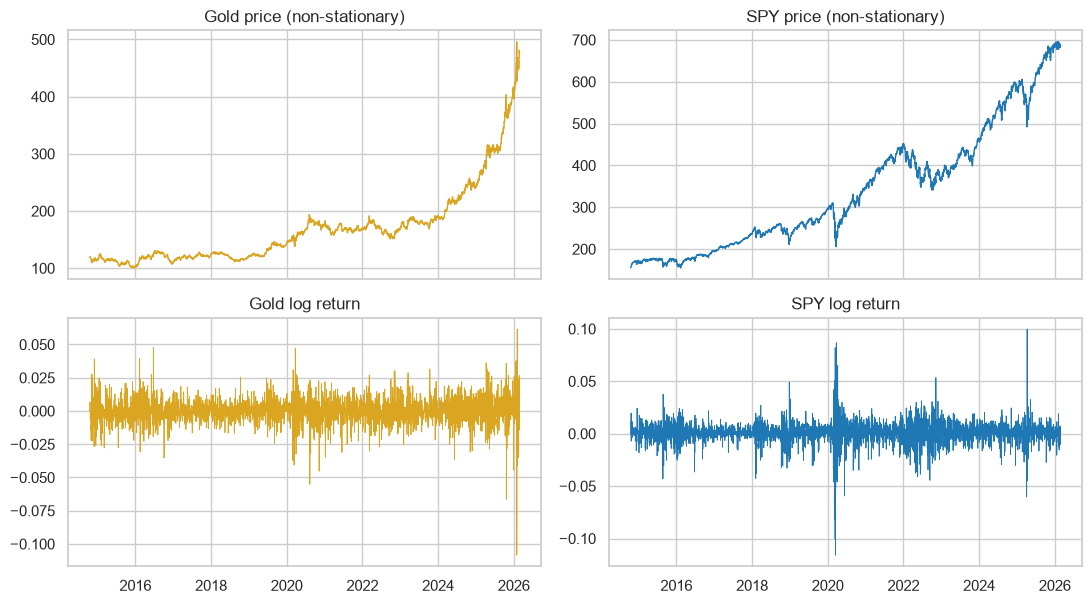

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True)
axes[0, 0].plot(df["Date"], df["Gold"], color="goldenrod", lw=1.0)
axes[0, 0].set_title("Gold price (non-stationary)")
axes[0, 1].plot(df["Date"], df["Equities_US"], color="tab:blue", lw=1.0)
axes[0, 1].set_title("SPY price (non-stationary)")
axes[1, 0].plot(df["Date"], df["gold_ret"], color="goldenrod", lw=0.6)
axes[1, 0].set_title("Gold log return")
axes[1, 1].plot(df["Date"], df["spy_ret"], color="tab:blue", lw=0.6)
axes[1, 1].set_title("SPY log return")
plt.tight_layout()
plt.savefig(FIG_DIR / "m1_prices_vs_returns.png", dpi=140, bbox_inches="tight")
plt.show()


## Milestone 1 regimes

- High stress: `High_Yield_Spread` above the sample median
- Inverted yield: `Yield_Curve_Spread < 0`


In [5]:
df["high_stress_median"] = (df["High_Yield_Spread"] > df["High_Yield_Spread"].median()).astype(int)
df["inverted_yield"] = (df["Yield_Curve_Spread"] < 0).astype(int)
print("median HYS:", float(df["High_Yield_Spread"].median()))
print("high-stress share:", round(float(df["high_stress_median"].mean()), 3))
print("inverted-yield share:", round(float(df["inverted_yield"].mean()), 3))


median HYS: 3.92
high-stress share: 0.497
inverted-yield share: 0.191


## Correlation heatmap — returns, stress, volatility


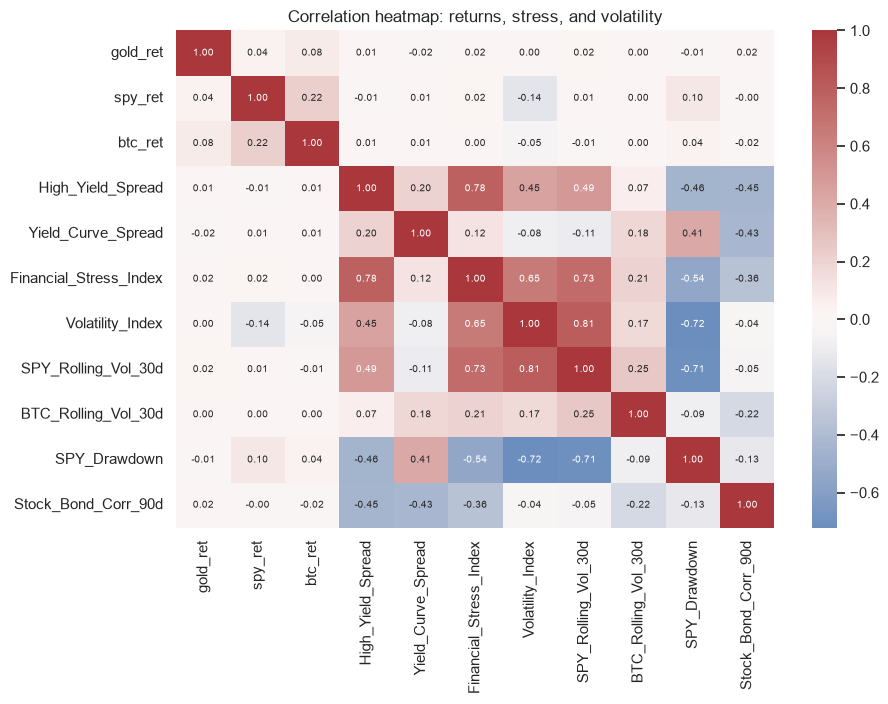

Gold return vs HYS: 0.008
VIX vs SPY 30d vol: 0.811


In [6]:
heat_cols = [
    "gold_ret", "spy_ret", "btc_ret",
    "High_Yield_Spread", "Yield_Curve_Spread", "Financial_Stress_Index",
    "Volatility_Index", "SPY_Rolling_Vol_30d", "BTC_Rolling_Vol_30d",
    "SPY_Drawdown", "Stock_Bond_Corr_90d",
]
corr = df[heat_cols].corr()
fig, ax = plt.subplots(figsize=(9.5, 7.2))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation heatmap: returns, stress, and volatility")
plt.tight_layout()
plt.savefig(FIG_DIR / "m1_heatmap.png", dpi=140, bbox_inches="tight")
plt.show()
print("Gold return vs HYS:", round(float(corr.loc["gold_ret", "High_Yield_Spread"]), 3))
print("VIX vs SPY 30d vol:", round(float(corr.loc["Volatility_Index", "SPY_Rolling_Vol_30d"]), 3))


## Gold-return boxplots and Welch t-test across the median-HYS split


Welch t = -0.6317, p = 0.5276
mean Gold return high-stress = 0.000253, low-stress = 0.000413


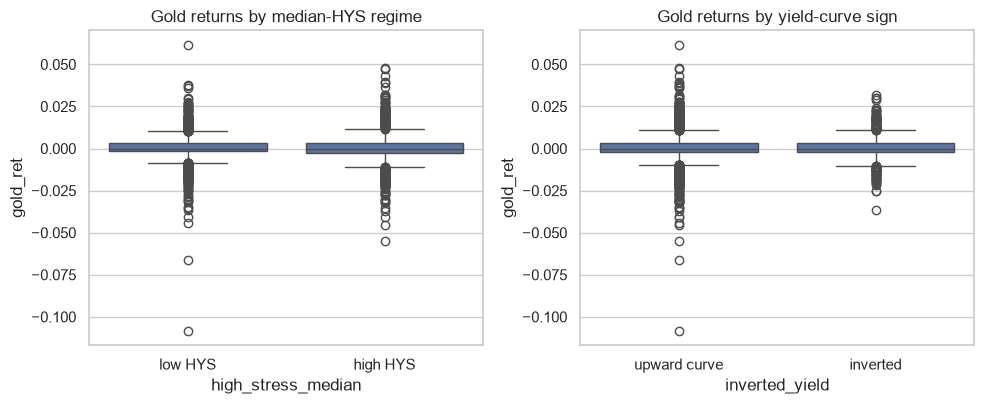

In [7]:
usable = df.dropna(subset=["gold_ret"]).copy()
high = usable.loc[usable["high_stress_median"] == 1, "gold_ret"]
low = usable.loc[usable["high_stress_median"] == 0, "gold_ret"]
t_stat, p_val = stats.ttest_ind(high, low, equal_var=False)
print(f"Welch t = {t_stat:.4f}, p = {p_val:.4f}")
print(f"mean Gold return high-stress = {high.mean():.6f}, low-stress = {low.mean():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
sns.boxplot(data=usable, x="high_stress_median", y="gold_ret", ax=axes[0])
axes[0].set_xticks([0, 1], ["low HYS", "high HYS"])
axes[0].set_title("Gold returns by median-HYS regime")
sns.boxplot(data=usable, x="inverted_yield", y="gold_ret", ax=axes[1])
axes[1].set_xticks([0, 1], ["upward curve", "inverted"])
axes[1].set_title("Gold returns by yield-curve sign")
plt.tight_layout()
plt.savefig(FIG_DIR / "m1_gold_boxplots.png", dpi=140, bbox_inches="tight")
plt.show()


## Granger causality: equity vs Gold, lags 1-10

Does lagged SPY return help predict Gold? And the reverse?


equity -> Gold (does lagged SPY help predict Gold?)


Gold -> equity (does lagged Gold help predict SPY?)


,lag,equity->Gold p,Gold->equity p
0,1,0.1063,0.3350
1,2,0.1301,0.6461
2,3,0.2533,0.5416
3,4,0.1161,0.5657
4,5,0.0748,0.6078
5,6,0.0029,0.6812
6,7,0.0034,0.7559
7,8,0.0005,0.7550
8,9,0.0011,0.6985
9,10,0.0022,0.7995


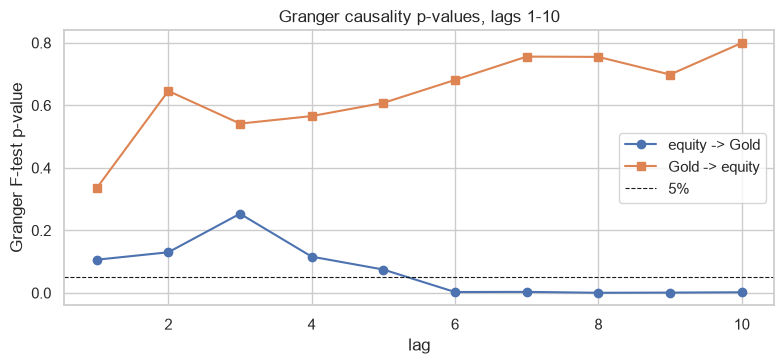

In [8]:
pair = df[["gold_ret", "spy_ret"]].dropna()
print("equity -> Gold (does lagged SPY help predict Gold?)")
g_eq_gold = grangercausalitytests(pair[["gold_ret", "spy_ret"]], maxlag=10)
print("Gold -> equity (does lagged Gold help predict SPY?)")
g_gold_eq = grangercausalitytests(pair[["spy_ret", "gold_ret"]], maxlag=10)
rows = []
for lag in range(1, 11):
    p_eq = g_eq_gold[lag][0]["ssr_ftest"][1]
    p_go = g_gold_eq[lag][0]["ssr_ftest"][1]
    rows.append({"lag": lag, "equity->Gold p": p_eq, "Gold->equity p": p_go})
g_table = pd.DataFrame(rows)
display(g_table.round(4))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(g_table["lag"], g_table["equity->Gold p"], "-o", label="equity -> Gold")
ax.plot(g_table["lag"], g_table["Gold->equity p"], "-s", label="Gold -> equity")
ax.axhline(0.05, color="k", ls="--", lw=0.8, label="5%")
ax.set_xlabel("lag"); ax.set_ylabel("Granger F-test p-value")
ax.set_title("Granger causality p-values, lags 1-10")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "m1_granger.png", dpi=140, bbox_inches="tight")
plt.show()


## Next-day Gold return: Zero vs Persistence vs Ridge

Chronological 80/20. Features are lagged returns, lagged stress, short rolling stats, and the M1 regime flags. Targets are shifted before the split.


In [9]:
m1 = df.copy()
m1["gold_ret_lag1"] = m1["gold_ret"].shift(1)
m1["gold_ret_lag3"] = m1["gold_ret"].shift(3)
m1["gold_ret_lag5"] = m1["gold_ret"].shift(5)
m1["spy_ret_lag1"] = m1["spy_ret"].shift(1)
m1["spy_ret_lag3"] = m1["spy_ret"].shift(3)
m1["spy_ret_lag5"] = m1["spy_ret"].shift(5)
m1["hys_lag1"] = m1["High_Yield_Spread"].shift(1)
m1["hys_lag5"] = m1["High_Yield_Spread"].shift(5)
m1["vix_lag1"] = m1["Volatility_Index"].shift(1)
m1["gold_rm5"] = m1["gold_ret"].rolling(5).mean()
m1["gold_rv5"] = m1["gold_ret"].rolling(5).std()
m1["y_gold_1"] = m1["gold_ret"].shift(-1)
GOLD_FEATS = [
    "gold_ret_lag1", "gold_ret_lag3", "gold_ret_lag5",
    "spy_ret_lag1", "spy_ret_lag3", "spy_ret_lag5",
    "hys_lag1", "hys_lag5", "vix_lag1",
    "Yield_Curve_Spread", "Financial_Stress_Index",
    "gold_rm5", "gold_rv5", "high_stress_median", "inverted_yield",
]
aligned = m1.dropna(subset=GOLD_FEATS + ["y_gold_1"]).reset_index(drop=True)
cut = int(len(aligned) * 0.8)
train, test = aligned.iloc[:cut], aligned.iloc[cut:]
assert train["Date"].max() < test["Date"].min()
print("train", train["Date"].min().date(), "->", train["Date"].max().date(), "n=", len(train))
print("test ", test["Date"].min().date(), "->", test["Date"].max().date(), "n=", len(test))
y_te = test["y_gold_1"].to_numpy()
zero = np.zeros_like(y_te)
persist = test["gold_ret"].to_numpy()
ridge = Pipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=1.0))])
ridge.fit(train[GOLD_FEATS], train["y_gold_1"])
ridge_hat = ridge.predict(test[GOLD_FEATS])

def reg_row(name, y_true, y_hat):
    return {
        "model": name,
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_hat))),
        "MAE": float(mean_absolute_error(y_true, y_hat)),
        "R2": float(r2_score(y_true, y_hat)),
    }

gold_tbl = pd.DataFrame([
    reg_row("Zero", y_te, zero),
    reg_row("Persistence", y_te, persist),
    reg_row("Ridge", y_te, ridge_hat),
])
display(gold_tbl.round(6))
print("Ridge does not beat the zero baseline on RMSE — next-day Gold is not linearly forecastable here.")


train 2014-10-23 -> 2023-11-18 n= 3314
test  2023-11-19 -> 2026-02-24 n= 829


,model,RMSE,MAE,R2
0,Zero,0.010732,0.006203,-0.011517
1,Persistence,0.015577,0.009987,-1.130830
2,Ridge,0.010696,0.006311,-0.004709


Ridge does not beat the zero baseline on RMSE — next-day Gold is not linearly forecastable here.


## SPY_Rolling_Vol_30d at h=5: Persistence vs Ridge vs Random Forest

Same chronological 80/20. Features are the current macro / market state plus current SPY vol.


train 2014-10-17 -> 2023-11-14 n= 3316
test  2023-11-15 -> 2026-02-20 n= 829


,model,RMSE,MAE,R2
0,Persistence,0.024754,0.012349,0.866611
1,Ridge,0.021671,0.012681,0.897763
2,Random Forest,0.026516,0.015761,0.846940


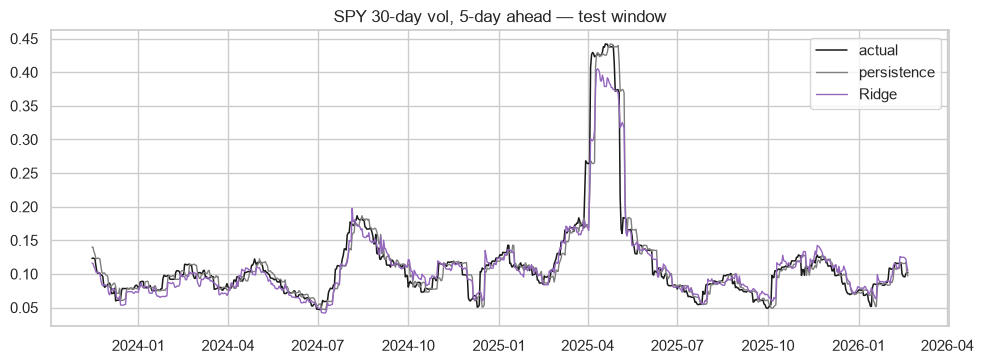

In [10]:
vol = df.copy()
vol["y_spy_vol_5"] = vol["SPY_Rolling_Vol_30d"].shift(-5)
VOL_FEATS = [
    "Volatility_Index", "Yield_Curve_Spread", "High_Yield_Spread",
    "Financial_Stress_Index", "Stock_Bond_Corr_90d", "SPY_Drawdown",
    "SPY_RSI_14", "SPY_Rolling_Vol_30d",
]
aligned_v = vol.dropna(subset=VOL_FEATS + ["y_spy_vol_5"]).reset_index(drop=True)
cut_v = int(len(aligned_v) * 0.8)
tr_v, te_v = aligned_v.iloc[:cut_v], aligned_v.iloc[cut_v:]
assert tr_v["Date"].max() < te_v["Date"].min()
print("train", tr_v["Date"].min().date(), "->", tr_v["Date"].max().date(), "n=", len(tr_v))
print("test ", te_v["Date"].min().date(), "->", te_v["Date"].max().date(), "n=", len(te_v))
y_v = te_v["y_spy_vol_5"].to_numpy()
persist_v = te_v["SPY_Rolling_Vol_30d"].to_numpy()
ridge_v = Pipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=1.0))])
ridge_v.fit(tr_v[VOL_FEATS], tr_v["y_spy_vol_5"])
rf_v = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_v.fit(tr_v[VOL_FEATS], tr_v["y_spy_vol_5"])
vol_tbl = pd.DataFrame([
    reg_row("Persistence", y_v, persist_v),
    reg_row("Ridge", y_v, ridge_v.predict(te_v[VOL_FEATS])),
    reg_row("Random Forest", y_v, rf_v.predict(te_v[VOL_FEATS])),
])
display(vol_tbl.round(6))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(te_v["Date"], y_v, color="k", lw=1.1, label="actual")
ax.plot(te_v["Date"], persist_v, color="tab:gray", lw=1.0, label="persistence")
ax.plot(te_v["Date"], ridge_v.predict(te_v[VOL_FEATS]), color="tab:purple", lw=1.0, label="Ridge")
ax.set_title("SPY 30-day vol, 5-day ahead — test window")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "m1_spy_vol_h5.png", dpi=140, bbox_inches="tight")
plt.show()


## Takeaway

- Price levels are non-stationary; log returns are the right object.
- A median high-yield-spread split does **not** move day-to-day Gold returns in a statistically significant way.
- Equity returns Granger-cause Gold at medium lags, but that does not yield a useful next-day linear forecast: Ridge does not beat a zero baseline.
- SPY 30-day volatility at h=5 **is** forecastable. Ridge improves on persistence.

The project therefore leaves "predict Gold tomorrow" and moves, in notebook 02, to explicit stress regimes and a direct safe-haven test: does Gold beat SPY on stressed days, and can we classify that event one day ahead?
